# EP2 Machine Learning — Caso A: Telco Customer Churn
**MLY1101** · Nicolás Garrido · Karen Manríquez · Felipe Espinoza

En este notebook desarrollamos el proyecto siguiendo las fases de **CRISP-DM**:
1. Comprensión del negocio
2. Comprensión de los datos (EDA)
3. Preparación de los datos
4. Modelado supervisado (Regresión Logística y Random Forest)
5. Modelado no supervisado (K-Means)
6. Evaluación
7. Guardado del modelo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve, silhouette_score)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Comprensión del negocio

La empresa pierde clientes todos los meses (churn). Queremos **predecir qué clientes van a abandonar** para que el área comercial les ofrezca algo antes de que se vayan.

- **Tipo de problema:** clasificación binaria (`Churn` = Yes / No).
- **Objetivo:** identificar a los clientes con mayor riesgo de abandono y entender qué los caracteriza.

**KPIs que vamos a medir:**
- Recall de la clase churn ≥ 0,75 (que el modelo no se le escapen los clientes que se van)
- ROC-AUC ≥ 0,80
- Lift del 20 % de clientes con más riesgo ≥ 2
- Capturar ≥ 70 % del ingreso mensual en riesgo
- Diferencia de recall entre hombres y mujeres < 5 puntos

## 2. Comprensión de los datos (EDA)

In [2]:
df = pd.read_csv("../data/Telco_Customer_Churn_Dataset.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Calidad de los datos

In [4]:
print("Nulos por columna:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

# TotalCharges viene como texto. Revisamos los valores que no se pueden convertir a número
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("TotalCharges vacíos:", df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Nulos por columna: 0
Filas duplicadas: 0
TotalCharges vacíos: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


No hay nulos ni duplicados, pero `TotalCharges` tiene **11 valores vacíos**. Todos tienen `tenure = 0`, o sea son clientes nuevos que todavía no han pagado nada, por eso los reemplazamos por **0** (no por la media).

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

### Variable objetivo

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


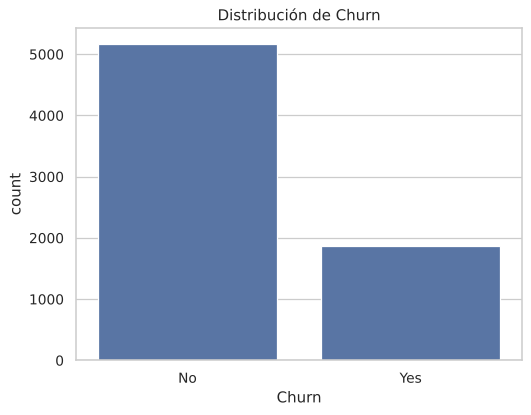

Ingreso mensual de los clientes que se van: 139131 USD
Porcentaje del ingreso total: 30.5 %


In [6]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="Churn")
plt.title("Distribución de Churn")
plt.savefig("../images/01_distribucion_churn.png", bbox_inches="tight")
plt.show()

ingreso_perdido = df[df["Churn"] == "Yes"]["MonthlyCharges"].sum()
print("Ingreso mensual de los clientes que se van:", round(ingreso_perdido), "USD")
print("Porcentaje del ingreso total:", round(ingreso_perdido / df["MonthlyCharges"].sum() * 100, 1), "%")

Los datos están **desbalanceados** (73 % No / 27 % Yes). Por eso no vamos a usar solo el accuracy para evaluar.

### Variables numéricas

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean     32.37           64.76       2279.73
std      24.56           30.09       2266.79
min       0.00           18.25          0.00
25%       9.00           35.50        398.55
50%      29.00           70.35       1394.55
75%      55.00           89.85       3786.60
max      72.00          118.75       8684.80


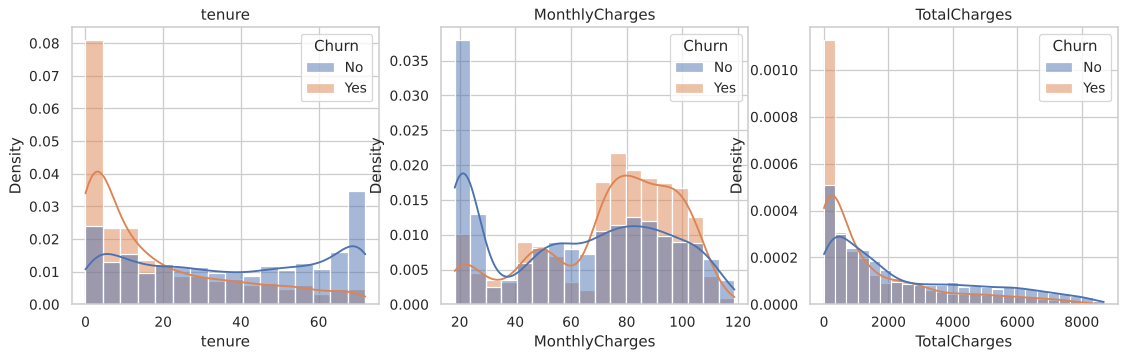

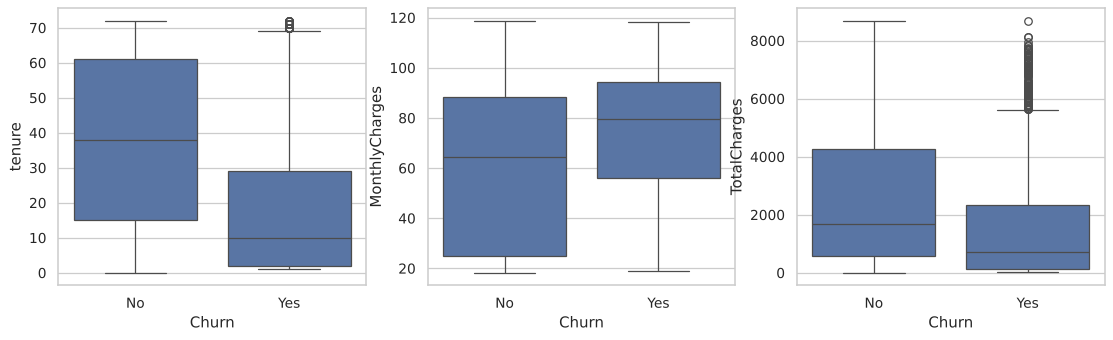

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.425,1679.525
Yes,10.0,79.650,703.550


In [7]:
numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
print(df[numericas].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(numericas):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, stat="density", common_norm=False, ax=axes[i])
    axes[i].set_title(col)
plt.savefig("../images/02_numericas_vs_churn.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(numericas):
    sns.boxplot(data=df, x="Churn", y=col, ax=axes[i])
plt.savefig("../images/03_boxplots_numericas.png", bbox_inches="tight")
plt.show()

df.groupby("Churn")[numericas].median()

- Los clientes que se van llevan **poco tiempo** en la empresa (mediana 10 meses vs 38).
- Pagan **más** al mes (mediana 80 vs 64 USD).
- No hay outliers raros, así que no eliminamos filas.

### Variables categóricas

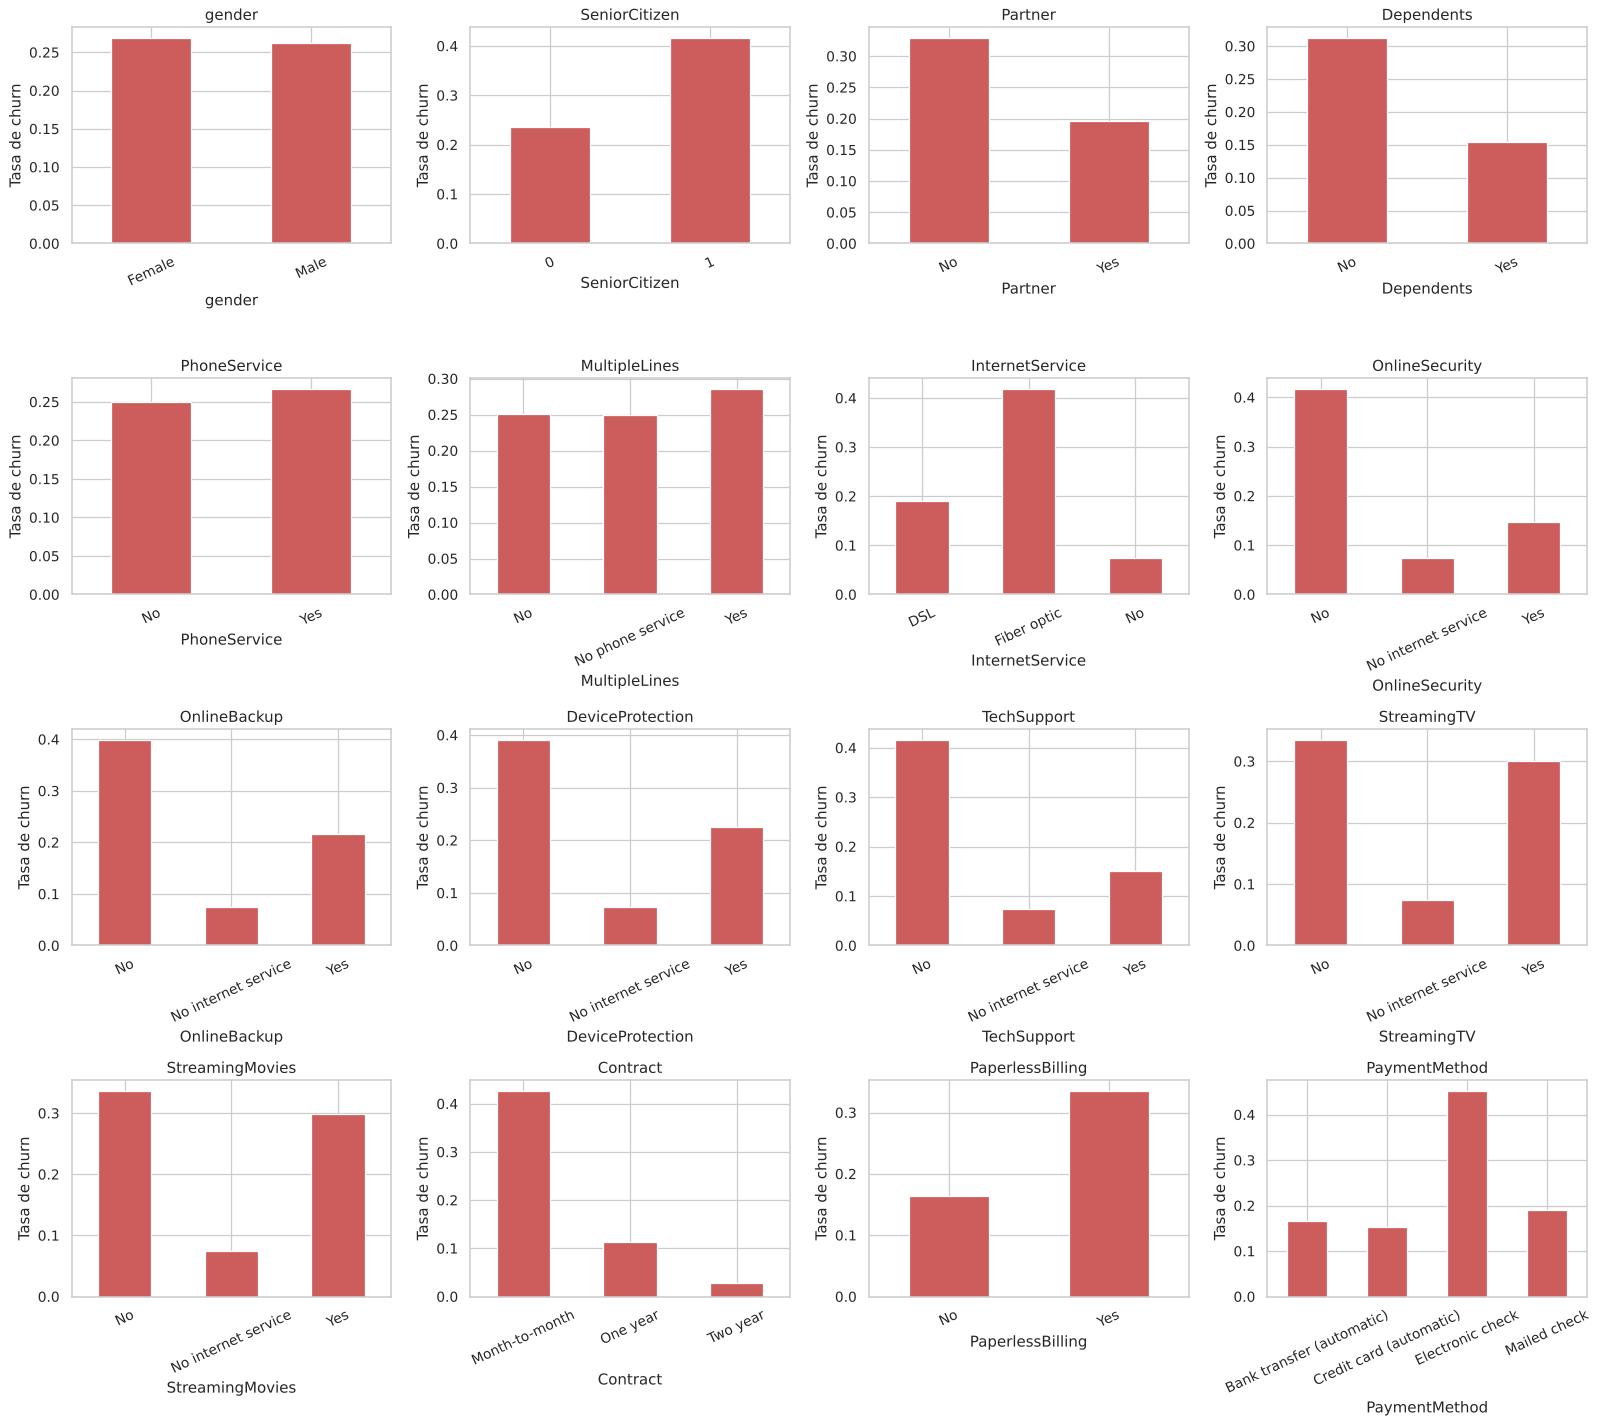

In [8]:
df["churn_num"] = (df["Churn"] == "Yes").astype(int)

categoricas = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
               "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
               "Contract", "PaperlessBilling", "PaymentMethod"]

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()
for i, col in enumerate(categoricas):
    tasa = df.groupby(col)["churn_num"].mean()
    tasa.plot(kind="bar", ax=axes[i], color="indianred")
    axes[i].set_title(col)
    axes[i].set_ylabel("Tasa de churn")
    axes[i].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig("../images/04_tasa_churn_categoricas.png", bbox_inches="tight")
plt.show()

In [9]:
# Diferencia entre la categoría con más churn y la con menos churn en cada variable
diferencias = {}
for col in categoricas:
    tasa = df.groupby(col)["churn_num"].mean()
    diferencias[col] = round(tasa.max() - tasa.min(), 3)
pd.Series(diferencias).sort_values(ascending=False)

Contract            0.399
InternetService     0.345
OnlineSecurity      0.344
TechSupport         0.342
OnlineBackup        0.325
DeviceProtection    0.317
PaymentMethod       0.300
StreamingMovies     0.263
StreamingTV         0.261
SeniorCitizen       0.181
PaperlessBilling    0.172
Dependents          0.158
Partner             0.133
MultipleLines       0.037
PhoneService        0.018
gender              0.008

Lo que más se relaciona con el churn:
- **Contrato mes a mes:** 43 % de churn (vs 11 % un año y 3 % dos años).
- **Fibra óptica:** 42 % (vs 19 % DSL).
- **Sin seguridad online ni soporte técnico:** ≈ 42 %.
- **Pago con cheque electrónico:** 45 %.
- **Adultos mayores** y clientes **sin pareja ni dependientes** también se van más.
- `gender` y `PhoneService` casi no cambian el churn.

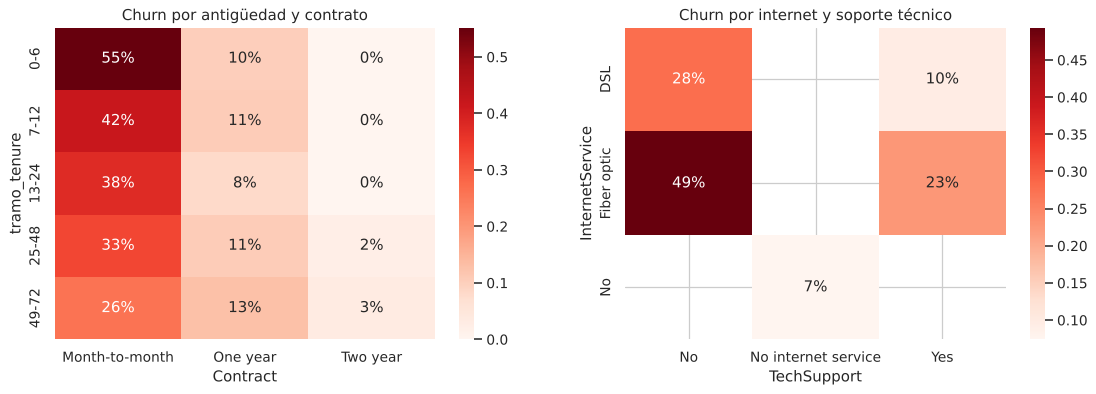

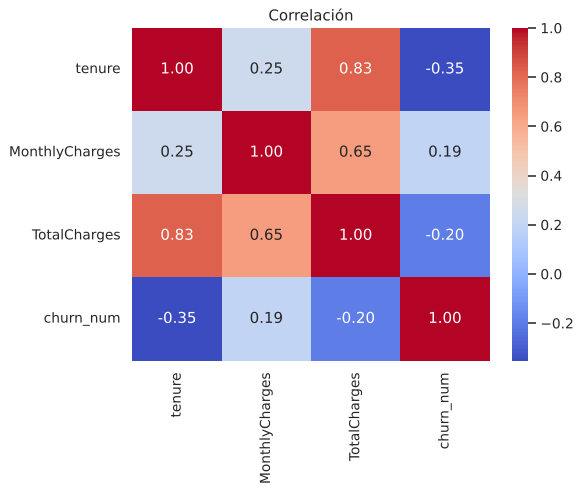

In [10]:
df["tramo_tenure"] = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(df.pivot_table(index="tramo_tenure", columns="Contract", values="churn_num"), annot=True, fmt=".0%", cmap="Reds", ax=axes[0])
axes[0].set_title("Churn por antigüedad y contrato")
sns.heatmap(df.pivot_table(index="InternetService", columns="TechSupport", values="churn_num"), annot=True, fmt=".0%", cmap="Reds", ax=axes[1])
axes[1].set_title("Churn por internet y soporte técnico")
plt.savefig("../images/05_interacciones.png", bbox_inches="tight")
plt.show()

sns.heatmap(df[numericas + ["churn_num"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlación")
plt.savefig("../images/06_correlacion_numericas.png", bbox_inches="tight")
plt.show()

- El peor caso es **contrato mes a mes con menos de 6 meses**.
- `TotalCharges` tiene una correlación de **0,83 con `tenure`**, o sea que repiten casi la misma información (multicolinealidad).

### Churn por tramos de antigüedad
*(Aporte de Karen)* Agrupamos `tenure` en tramos de un año o más para ver cómo cambia el riesgo con el tiempo.

                  tasa_churn  clientes
tramo_antiguedad                      
0-12 m                 0.474      2186
13-24 m                0.287      1024
25-48 m                0.204      1594
49-72 m                0.095      2239


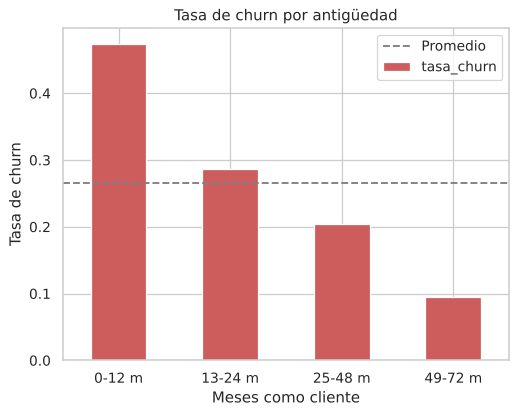

In [11]:
df["tramo_antiguedad"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
tramos = df.groupby("tramo_antiguedad", observed=True)["churn_num"].agg(["mean", "count"])
tramos.columns = ["tasa_churn", "clientes"]
print(tramos.round(3))

tramos["tasa_churn"].plot(kind="bar", color="indianred", rot=0)
plt.axhline(df["churn_num"].mean(), ls="--", color="gray", label="Promedio")
plt.title("Tasa de churn por antigüedad"); plt.ylabel("Tasa de churn"); plt.xlabel("Meses como cliente"); plt.legend()
plt.savefig("../images/14_churn_por_tramo_antiguedad.png", bbox_inches="tight")
plt.show()

Casi **la mitad (47 %)** de los clientes con 12 meses o menos se va, y en los que llevan más de 4 años baja a **menos del 10 %**. El primer año es el momento clave para retenerlos.

## 3. Preparación de los datos

Pasos que hicimos:
1. Sacamos `customerID` (no sirve para predecir) y `gender` (no influye en el churn y es un dato sensible, lo dejamos aparte solo para revisar sesgo al final).
2. Sacamos `TotalCharges` porque está muy correlacionada con `tenure`.
3. Cambiamos "No internet service" y "No phone service" por "No".
4. `SeniorCitizen` pasa de 0/1 a No/Yes para tratarla como categórica.
5. Dividimos en **80 % train y 20 % test** con `stratify` para mantener la proporción de churn.
6. Escalamos las numéricas con `StandardScaler` y aplicamos One-Hot Encoding a las categóricas, dentro de un `Pipeline` para que solo aprenda de train.

También creamos algunas variables nuevas (`num_servicios`, `pago_automatico`) que usamos después en el K-Means.

In [12]:
servicios = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "MultipleLines"]

def ingenieria_variables(data):
    d = data.copy()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce").fillna(0)
    d["SeniorCitizen"] = d["SeniorCitizen"].map({0: "No", 1: "Yes"})
    d = d.replace({"No internet service": "No", "No phone service": "No"})
    d["num_servicios"] = (d[servicios] == "Yes").sum(axis=1)
    d["pago_automatico"] = np.where(d["PaymentMethod"].str.contains("automatic"), "Yes", "No")
    return d

datos = ingenieria_variables(pd.read_csv("../data/Telco_Customer_Churn_Dataset.csv"))

y = (datos["Churn"] == "Yes").astype(int)
grupos = datos[["gender", "SeniorCitizen"]]   # solo para revisar sesgo
X = datos.drop(columns=["customerID", "Churn", "gender", "TotalCharges", "num_servicios", "pago_automatico"])

col_numericas = ["tenure", "MonthlyCharges"]
col_categoricas = [c for c in X.columns if c not in col_numericas]

X_train, X_test, y_train, y_test, g_train, g_test = train_test_split(
    X, y, grupos, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn en train:", round(y_train.mean(), 3), " Churn en test:", round(y_test.mean(), 3))

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), col_numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), col_categoricas),
])

Train: (5634, 17)  Test: (1409, 17)
Churn en train: 0.265  Churn en test: 0.265


Comprobamos que sacar `TotalCharges` no empeora el modelo (ROC-AUC con validación cruzada):

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

X_con_total = X_train.join(datos[["TotalCharges"]])
prep_con_total = ColumnTransformer([
    ("num", StandardScaler(), ["tenure", "MonthlyCharges", "TotalCharges"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), col_categoricas),
])
lr_con = Pipeline([("prep", prep_con_total), ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000))])
lr_sin = Pipeline([("prep", preprocesador), ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000))])

print("Con TotalCharges:", round(cross_val_score(lr_con, X_con_total, y_train, cv=cv, scoring="roc_auc").mean(), 4))
print("Sin TotalCharges:", round(cross_val_score(lr_sin, X_train, y_train, cv=cv, scoring="roc_auc").mean(), 4))

Con TotalCharges: 0.8461
Sin TotalCharges: 0.8449


Casi no cambia, así que la dejamos fuera.

## 4. Modelado supervisado

Probamos dos modelos:
- **Regresión Logística:** es simple y se puede interpretar con sus coeficientes.
- **Random Forest:** puede captar relaciones no lineales entre variables.

En los dos usamos `class_weight="balanced"` por el desbalance, y buscamos los mejores hiperparámetros con **GridSearchCV** (5 folds, métrica ROC-AUC). También entrenamos un modelo **Dummy** como base de comparación.

In [14]:
pipe_lr = Pipeline([("prep", preprocesador),
                    ("modelo", LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=2000, random_state=RANDOM_STATE))])
params_lr = {"modelo__C": [0.01, 0.1, 0.5, 1, 5], "modelo__penalty": ["l1", "l2"]}

grid_lr = GridSearchCV(pipe_lr, params_lr, scoring="roc_auc", cv=cv, n_jobs=-1)
grid_lr.fit(X_train, y_train)
print("Regresión Logística -> mejor ROC-AUC CV:", round(grid_lr.best_score_, 4), grid_lr.best_params_)

Regresión Logística -> mejor ROC-AUC CV: 0.8451 {'modelo__C': 5, 'modelo__penalty': 'l2'}


In [15]:
pipe_rf = Pipeline([("prep", preprocesador),
                    ("modelo", RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))])
params_rf = {"modelo__n_estimators": [300], "modelo__max_depth": [6, 10, None],
             "modelo__min_samples_leaf": [5, 10, 20], "modelo__max_features": ["sqrt", 0.3]}

grid_rf = GridSearchCV(pipe_rf, params_rf, scoring="roc_auc", cv=cv, n_jobs=-1)
grid_rf.fit(X_train, y_train)
print("Random Forest -> mejor ROC-AUC CV:", round(grid_rf.best_score_, 4), grid_rf.best_params_)

Random Forest -> mejor ROC-AUC CV: 0.8476 {'modelo__max_depth': None, 'modelo__max_features': 0.3, 'modelo__min_samples_leaf': 20, 'modelo__n_estimators': 300}


In [16]:
dummy = Pipeline([("prep", preprocesador), ("modelo", DummyClassifier(strategy="most_frequent"))])
dummy.fit(X_train, y_train)

modelos = {"Baseline (Dummy)": dummy,
           "Regresión Logística": grid_lr.best_estimator_,
           "Random Forest": grid_rf.best_estimator_}

### Umbral de decisión
En vez de usar 0,5 buscamos el umbral que da el mejor F1 con un recall de al menos 0,75. Para no usar el test, lo calculamos con las predicciones de validación cruzada sobre train.

In [17]:
umbrales = {"Baseline (Dummy)": 0.5}
for nombre in ["Regresión Logística", "Random Forest"]:
    prob_cv = cross_val_predict(modelos[nombre], X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    precision, recall, thr = precision_recall_curve(y_train, prob_cv)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    f1[recall < 0.75] = -1            # descartamos umbrales con recall menor a 0,75
    mejor = np.argmax(f1[:-1])
    umbrales[nombre] = thr[mejor]
    print(nombre, "-> umbral:", round(thr[mejor], 3), " recall:", round(recall[mejor], 3))

Regresión Logística -> umbral: 0.557  recall: 0.754
Random Forest -> umbral: 0.541  recall: 0.759


### Resultados en test

In [18]:
resultados = []
probas, preds = {}, {}
for nombre, modelo in modelos.items():
    prob = modelo.predict_proba(X_test)[:, 1]
    pred = (prob >= umbrales[nombre]).astype(int)
    probas[nombre], preds[nombre] = prob, pred

    top20 = np.argsort(-prob)[:int(len(y_test) * 0.2)]          # 20 % con mayor probabilidad
    lift = y_test.values[top20].mean() / y_test.mean()

    resultados.append([nombre, umbrales[nombre], accuracy_score(y_test, pred), precision_score(y_test, pred, zero_division=0),
                       recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob),
                       average_precision_score(y_test, prob), lift])

resultados = pd.DataFrame(resultados, columns=["Modelo", "Umbral", "Accuracy", "Precision", "Recall", "F1",
                                               "ROC-AUC", "PR-AUC", "Lift top 20%"]).set_index("Modelo").round(3)
resultados.to_csv("../models/metricas_test.csv")
resultados

,Umbral,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Lift top 20%
Modelo,,,,,,,,
Baseline (Dummy),0.500,0.735,0.000,0.000,0.000,0.500,0.265,1.046
Regresión Logística,0.557,0.752,0.524,0.733,0.611,0.839,0.629,2.507
Random Forest,0.541,0.765,0.541,0.759,0.632,0.846,0.651,2.494


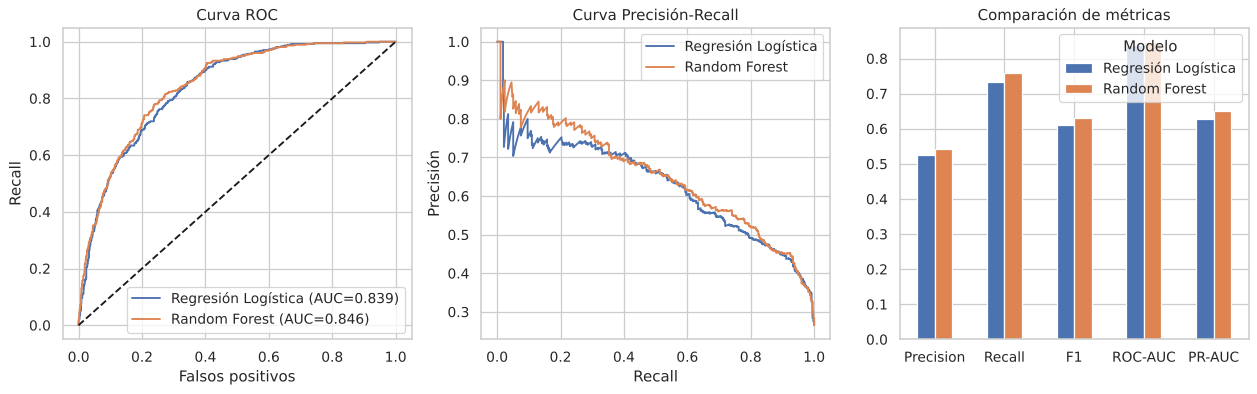

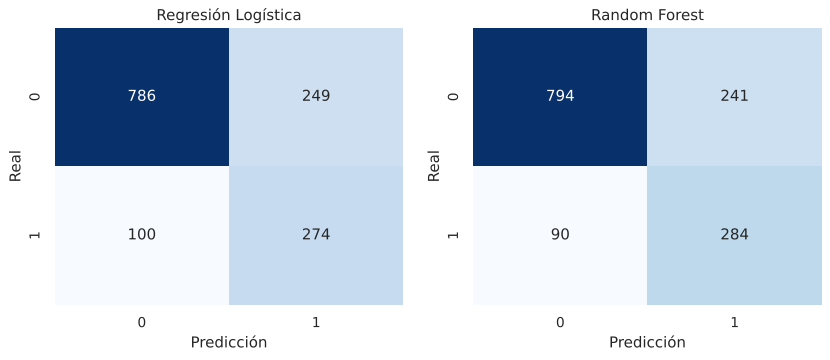

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for nombre in ["Regresión Logística", "Random Forest"]:
    fpr, tpr, _ = roc_curve(y_test, probas[nombre])
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(y_test, probas[nombre]):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, probas[nombre])
    axes[1].plot(rec, prec, label=nombre)
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_title("Curva ROC"); axes[0].set_xlabel("Falsos positivos"); axes[0].set_ylabel("Recall"); axes[0].legend()
axes[1].set_title("Curva Precisión-Recall"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precisión"); axes[1].legend()
resultados.loc[["Regresión Logística", "Random Forest"], ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]].T.plot(kind="bar", ax=axes[2], rot=0)
axes[2].set_title("Comparación de métricas")
plt.savefig("../images/07_roc_pr_comparacion.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, nombre in enumerate(["Regresión Logística", "Random Forest"]):
    sns.heatmap(confusion_matrix(y_test, preds[nombre]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i])
    axes[i].set_title(nombre); axes[i].set_xlabel("Predicción"); axes[i].set_ylabel("Real")
plt.savefig("../images/08_matrices_confusion.png", bbox_inches="tight")
plt.show()

Los dos modelos superan claramente al Dummy (AUC 0,50). El **Random Forest** queda un poco mejor: AUC 0,846, recall 0,759 y F1 0,632, y es el único que cumple el KPI de recall ≥ 0,75. La Regresión Logística queda con recall 0,733.

### ¿Qué variables influyen más?

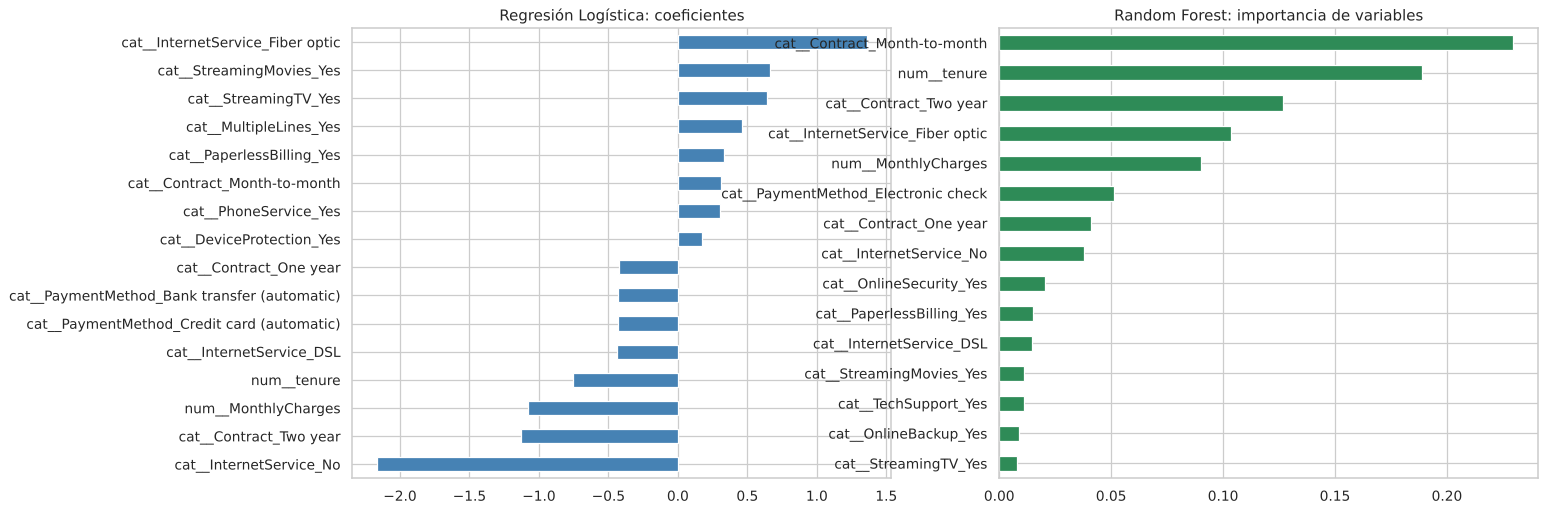

Odds ratio (exp del coeficiente):
cat__InternetService_Fiber optic    3.90
cat__Contract_Two year              0.32
num__tenure                         0.47
dtype: float64


In [20]:
lr = modelos["Regresión Logística"]
coef = pd.Series(lr.named_steps["modelo"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out()).sort_values()

rf = modelos["Random Forest"]
importancia = pd.Series(rf.named_steps["modelo"].feature_importances_, index=rf.named_steps["prep"].get_feature_names_out()).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
pd.concat([coef.head(8), coef.tail(8)]).plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Regresión Logística: coeficientes")
importancia.tail(15).plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].set_title("Random Forest: importancia de variables")
plt.savefig("../images/09_importancia_variables.png", bbox_inches="tight")
plt.show()

print("Odds ratio (exp del coeficiente):")
print(np.exp(coef).round(2).loc[["cat__InternetService_Fiber optic", "cat__Contract_Two year", "num__tenure"]])

- Lo que más aumenta el churn: **fibra óptica** (odds × 3,9), contrato mes a mes, streaming.
- Lo que más lo reduce: **contrato de 2 años** (odds × 0,32), más antigüedad, no tener internet.
- En la logística `MonthlyCharges` sale negativo porque el precio ya está explicado por los servicios contratados (fibra, streaming), que salen positivos.

### Modelo de control: ¿un modelo más complejo mejora?
*(Aporte de Karen)* Probamos un tercer modelo, **Gradient Boosting** (`HistGradientBoostingClassifier`), que suele ser de los más fuertes en datos tabulares. Lo usamos solo como **control**: si no mejora claramente, nos quedamos con los dos modelos anteriores. Usamos el mismo preprocesamiento, `class_weight="balanced"`, GridSearchCV y la misma regla para el umbral.

In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier

pipe_hgb = Pipeline([("prep", preprocesador),
                     ("modelo", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE))])
params_hgb = {"modelo__learning_rate": [0.05, 0.1], "modelo__max_depth": [3, 6], "modelo__min_samples_leaf": [20, 50]}

grid_hgb = GridSearchCV(pipe_hgb, params_hgb, scoring="roc_auc", cv=cv, n_jobs=-1)
grid_hgb.fit(X_train, y_train)
print("Gradient Boosting -> mejor ROC-AUC CV:", round(grid_hgb.best_score_, 4), grid_hgb.best_params_)

# Umbral con la misma regla (mejor F1 con recall >= 0,75, calculado en train)
prob_cv = cross_val_predict(grid_hgb.best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
precision, recall, thr = precision_recall_curve(y_train, prob_cv)
f1 = 2 * precision * recall / (precision + recall + 1e-9)
f1[recall < 0.75] = -1
umbral_hgb = thr[np.argmax(f1[:-1])]

prob_hgb = grid_hgb.best_estimator_.predict_proba(X_test)[:, 1]
pred_hgb = (prob_hgb >= umbral_hgb).astype(int)
top20 = np.argsort(-prob_hgb)[:int(len(y_test) * 0.2)]

fila_hgb = pd.DataFrame([[umbral_hgb, accuracy_score(y_test, pred_hgb), precision_score(y_test, pred_hgb),
                          recall_score(y_test, pred_hgb), f1_score(y_test, pred_hgb), roc_auc_score(y_test, prob_hgb),
                          average_precision_score(y_test, prob_hgb), y_test.values[top20].mean() / y_test.mean()]],
                        columns=resultados.columns, index=["Gradient Boosting (control)"])
pd.concat([resultados, fila_hgb.round(3)])

Gradient Boosting -> mejor ROC-AUC CV: 0.8482 {'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 50}


,Umbral,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Lift top 20%
Baseline (Dummy),0.500,0.735,0.000,0.000,0.000,0.500,0.265,1.046
Regresión Logística,0.557,0.752,0.524,0.733,0.611,0.839,0.629,2.507
Random Forest,0.541,0.765,0.541,0.759,0.632,0.846,0.651,2.494
Gradient Boosting (control),0.519,0.752,0.521,0.789,0.628,0.845,0.658,2.507


El Gradient Boosting queda **prácticamente igual** que el Random Forest:
- En validación cruzada saca 0,8482 vs 0,8476 del Random Forest (una diferencia de 0,0006).
- En test gana en algunas métricas (recall 0,789, PR-AUC 0,658) y pierde en otras (ROC-AUC 0,845, F1 0,628, precisión 0,521).

Como no mejora de forma clara, **nos quedamos con el Random Forest**, que es más fácil de explicar. Esto también muestra que el límite lo ponen los datos disponibles, no el algoritmo.

## 5. Modelo no supervisado: K-Means

Usamos K-Means para agrupar a los clientes **sin usar la columna Churn**, y después vemos cuánto churn tiene cada grupo.

Variables: `tenure`, `MonthlyCharges`, `num_servicios`, tipo de contrato (0, 1, 2), si tiene fibra y si paga automático. Las escalamos porque K-Means usa distancias.

k = 2  inercia = 29489  silueta = 0.293
k = 3  inercia = 21035  silueta = 0.331
k = 4  inercia = 16964  silueta = 0.337
k = 5  inercia = 14485  silueta = 0.351
k = 6  inercia = 12775  silueta = 0.363
k = 7  inercia = 11103  silueta = 0.383
k = 8  inercia = 9910  silueta = 0.386


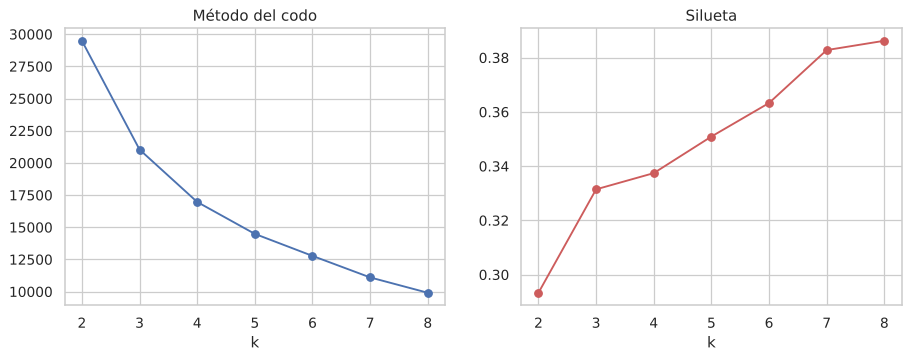

In [22]:
seg = datos.copy()
seg["contrato_ord"] = seg["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})
seg["fibra"] = (seg["InternetService"] == "Fiber optic").astype(int)
seg["pago_auto"] = (seg["pago_automatico"] == "Yes").astype(int)
variables_seg = ["tenure", "MonthlyCharges", "num_servicios", "contrato_ord", "fibra", "pago_auto"]

escalador_seg = StandardScaler()
Z = escalador_seg.fit_transform(seg[variables_seg])

inercias, siluetas = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z, km.labels_, sample_size=3000, random_state=RANDOM_STATE))
    print("k =", k, " inercia =", round(km.inertia_), " silueta =", round(siluetas[-1], 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(2, 9), inercias, "o-"); axes[0].set_title("Método del codo"); axes[0].set_xlabel("k")
axes[1].plot(range(2, 9), siluetas, "o-", color="indianred"); axes[1].set_title("Silueta"); axes[1].set_xlabel("k")
plt.savefig("../images/10_eleccion_k.png", bbox_inches="tight")
plt.show()

El codo está entre k = 3 y k = 4, y con k = 4 los grupos se pueden interpretar bien, así que elegimos **k = 4**.

In [23]:
kmeans = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit(Z)
seg["segmento"] = kmeans.labels_
print("Silueta k=4:", round(silhouette_score(Z, kmeans.labels_), 3))

nombres = {0: "S0 Fibra mes a mes", 1: "S1 Básicos nuevos mes a mes", 2: "S2 Básicos con contrato", 3: "S3 Premium leales"}
seg["segmento_nombre"] = seg["segmento"].map(nombres)

perfil = seg.groupby("segmento_nombre").agg(
    clientes=("customerID", "count"),
    tenure_medio=("tenure", "mean"),
    cargo_medio=("MonthlyCharges", "mean"),
    servicios=("num_servicios", "mean"),
    pct_fibra=("fibra", "mean"),
    tasa_churn=("Churn", lambda x: (x == "Yes").mean()))
perfil["ingreso_en_riesgo"] = seg[seg["Churn"] == "Yes"].groupby("segmento_nombre")["MonthlyCharges"].sum()
perfil = perfil.sort_values("tasa_churn", ascending=False).round(2)
perfil

Silueta k=4: 0.332


,clientes,tenure_medio,cargo_medio,servicios,pct_fibra,tasa_churn,ingreso_en_riesgo
segmento_nombre,,,,,,,
S0 Fibra mes a mes,2157,20.63,86.54,2.40,1.00,0.54,100397.50
S1 Básicos nuevos mes a mes,2008,13.81,40.40,1.24,0.00,0.25,21243.55
S3 Premium leales,1659,59.61,91.15,5.07,0.57,0.10,16070.55
S2 Básicos con contrato,1219,46.65,30.44,1.02,0.00,0.03,1419.25


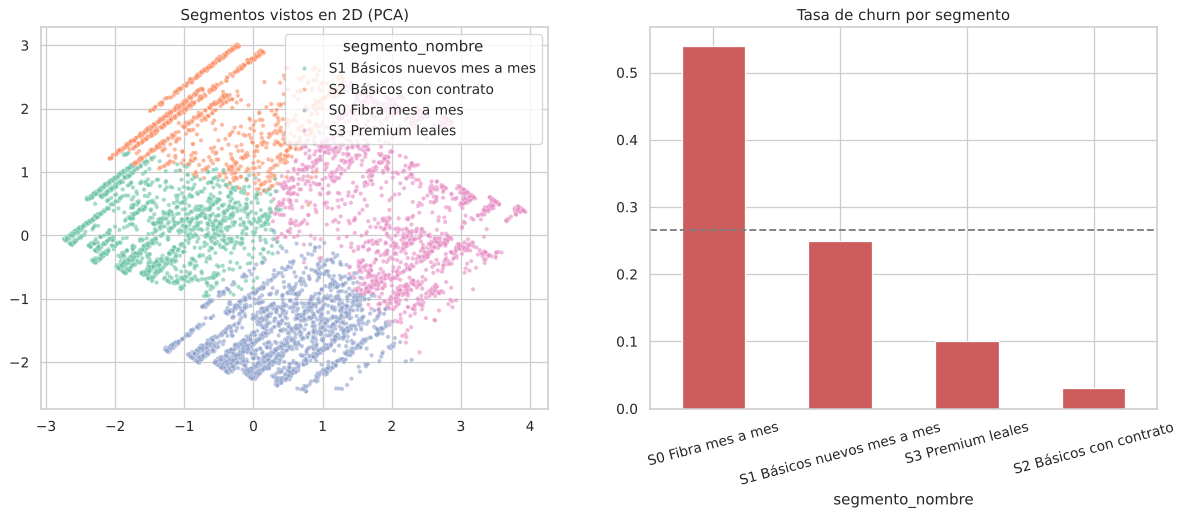

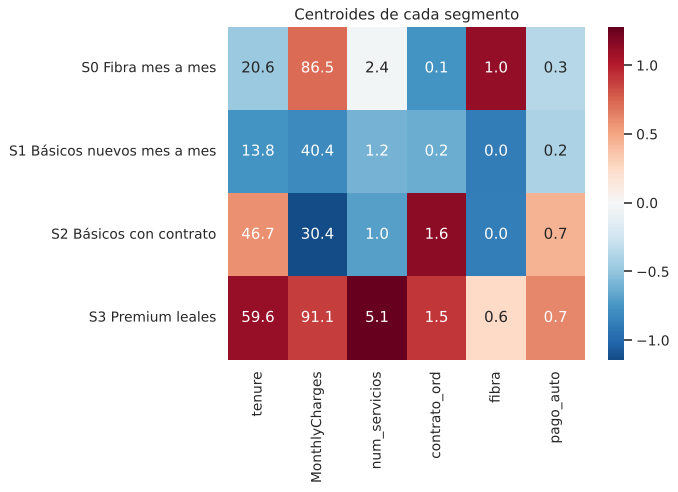

In [24]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Z)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=seg["segmento_nombre"], s=12, alpha=0.6, palette="Set2", ax=axes[0])
axes[0].set_title("Segmentos vistos en 2D (PCA)")
perfil["tasa_churn"].plot(kind="bar", ax=axes[1], color="indianred", rot=15)
axes[1].axhline(y.mean(), ls="--", color="gray")
axes[1].set_title("Tasa de churn por segmento")
plt.savefig("../images/11_segmentos_kmeans.png", bbox_inches="tight")
plt.show()

centroides = pd.DataFrame(escalador_seg.inverse_transform(kmeans.cluster_centers_), columns=variables_seg,
                          index=[nombres[i] for i in range(4)])
sns.heatmap(pd.DataFrame(kmeans.cluster_centers_, columns=variables_seg, index=centroides.index),
            annot=centroides.round(1), fmt="", cmap="RdBu_r", center=0)
plt.title("Centroides de cada segmento")
plt.savefig("../images/12_centroides_kmeans.png", bbox_inches="tight")
plt.show()

| Segmento | Descripción | Churn | Qué hacer |
|---|---|---|---|
| S0 Fibra mes a mes | Fibra, contrato mensual, ~USD 87 | **54 %** | Prioridad: ofrecer contrato anual con descuento |
| S1 Básicos nuevos mes a mes | DSL o solo teléfono, poco tiempo | 25 % | Ofrecer soporte/seguridad, acompañar el primer año |
| S3 Premium leales | Muchos servicios, varios años | 10 % | Fidelizar |
| S2 Básicos con contrato | Contrato largo, cargo bajo | 3 % | No gastar en retención |

El segmento **S0** concentra cerca del **72 % del ingreso en riesgo**.

## 6. Evaluación

### Modelo elegido
Elegimos el que tuvo mejor ROC-AUC en validación cruzada.

In [25]:
auc_cv = {"Regresión Logística": grid_lr.best_score_, "Random Forest": grid_rf.best_score_}
MODELO_FINAL = max(auc_cv, key=auc_cv.get)
print(auc_cv)
print("Modelo final:", MODELO_FINAL)

{'Regresión Logística': np.float64(0.8450649388847559), 'Random Forest': np.float64(0.8475797447836362)}
Modelo final: Random Forest


### ¿Hay sobreajuste?
*(Aporte de Karen)* Comparamos el ROC-AUC en train, en validación cruzada y en test. Si el modelo memorizara los datos de entrenamiento, el valor en train sería mucho más alto que en test.

In [26]:
modelos_revisar = {"Regresión Logística": grid_lr, "Random Forest": grid_rf, "Gradient Boosting (control)": grid_hgb}
filas = []
for nombre, grid in modelos_revisar.items():
    auc_train = roc_auc_score(y_train, grid.best_estimator_.predict_proba(X_train)[:, 1])
    auc_test = roc_auc_score(y_test, grid.best_estimator_.predict_proba(X_test)[:, 1])
    filas.append([nombre, auc_train, grid.best_score_, auc_test, auc_train - auc_test])
pd.DataFrame(filas, columns=["Modelo", "ROC-AUC train", "ROC-AUC CV", "ROC-AUC test", "Diferencia train - test"]).set_index("Modelo").round(3)

,ROC-AUC train,ROC-AUC CV,ROC-AUC test,Diferencia train - test
Modelo,,,,
Regresión Logística,0.848,0.845,0.839,0.009
Random Forest,0.880,0.848,0.846,0.034
Gradient Boosting (control),0.863,0.848,0.845,0.018


- Los tres modelos tienen valores muy parecidos en validación cruzada y en test, así que **generalizan bien**.
- El Random Forest es el que más se ajusta a train (0,880 vs 0,846 en test), pero la diferencia es solo de **0,034**, así que no hay un sobreajuste importante.
- La Regresión Logística casi no tiene diferencia (0,009) porque es un modelo más simple.

### Impacto en el negocio
Simulamos una campaña de retención en el test con estos **supuestos**: contactar a un cliente cuesta USD 50, la retención funciona en el 35 % de los casos y retener a un cliente vale 12 meses de su cargo mensual.

In [27]:
COSTO, EXITO, MESES = 50, 0.35, 12
cargo = X_test["MonthlyCharges"].values

def campana(contactar):
    contactar = np.array(contactar, dtype=bool)
    detectados = contactar & (y_test.values == 1)
    ingreso = cargo[detectados].sum() * MESES * EXITO
    costo = contactar.sum() * COSTO
    return [contactar.sum(), detectados.sum(), cargo[detectados].sum() / cargo[y_test.values == 1].sum(), ingreso, costo, ingreso - costo]

escenarios = {"No hacer nada": np.zeros(len(y_test)), "Contactar a todos": np.ones(len(y_test)),
              "Regresión Logística": preds["Regresión Logística"], "Random Forest": preds["Random Forest"]}
impacto = pd.DataFrame([campana(v) for v in escenarios.values()], index=escenarios.keys(),
                       columns=["contactados", "churners_detectados", "% ingreso en riesgo capturado", "ingreso_retenido", "costo", "beneficio_neto"])
impacto.round(2)

,contactados,churners_detectados,% ingreso en riesgo capturado,ingreso_retenido,costo,beneficio_neto
No hacer nada,0,0,0.00,0.00,0,0.00
Contactar a todos,1409,374,1.00,114302.58,70450,43852.58
Regresión Logística,523,274,0.77,88479.51,26150,62329.51
Random Forest,525,284,0.78,89504.94,26250,63254.94


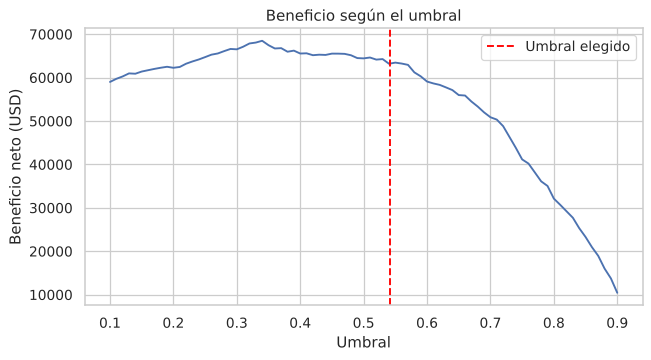

Mejor umbral para el beneficio: 0.34  beneficio: 68487


In [28]:
umbrales_prueba = np.linspace(0.1, 0.9, 81)
beneficios = [campana(probas[MODELO_FINAL] >= u)[-1] for u in umbrales_prueba]

plt.figure(figsize=(8, 4))
plt.plot(umbrales_prueba, beneficios)
plt.axvline(umbrales[MODELO_FINAL], ls="--", color="red", label="Umbral elegido")
plt.xlabel("Umbral"); plt.ylabel("Beneficio neto (USD)"); plt.title("Beneficio según el umbral"); plt.legend()
plt.savefig("../images/13_beneficio_vs_umbral.png", bbox_inches="tight")
plt.show()

print("Mejor umbral para el beneficio:", round(umbrales_prueba[np.argmax(beneficios)], 2), " beneficio:", round(max(beneficios)))

Con el Random Forest se contacta solo al **37 %** de los clientes y se captura el **78 % del ingreso en riesgo**. El beneficio es **≈ USD 63.000**, un 44 % más que contactar a todos. Si el contacto fuera más barato convendría bajar el umbral (≈ 0,34).

### Revisión ética
Sacamos `gender` del modelo, pero revisamos si el modelo funciona igual para hombres y mujeres, y para adultos mayores.

In [29]:
filas = []
for col in ["gender", "SeniorCitizen"]:
    for valor in g_test[col].unique():
        m = (g_test[col] == valor).values
        tn, fp, fn, tp = confusion_matrix(y_test[m], preds[MODELO_FINAL][m]).ravel()
        filas.append([col, valor, m.sum(), tp / (tp + fn), fp / (fp + tn)])
pd.DataFrame(filas, columns=["variable", "grupo", "n", "recall", "tasa_falsos_positivos"]).round(3)

,variable,grupo,n,recall,tasa_falsos_positivos
0,gender,Male,722,0.790,0.244
1,gender,Female,687,0.731,0.221
2,SeniorCitizen,No,1187,0.728,0.207
3,SeniorCitizen,Yes,222,0.847,0.419


In [30]:
# ¿La diferencia de recall entre mujeres y hombres es significativa? (test z de dos proporciones)
from scipy.stats import norm
churn_f = (g_test["gender"] == "Female").values & (y_test.values == 1)
churn_m = (g_test["gender"] == "Male").values & (y_test.values == 1)
r_f, r_m = preds[MODELO_FINAL][churn_f].mean(), preds[MODELO_FINAL][churn_m].mean()
p = (r_f * churn_f.sum() + r_m * churn_m.sum()) / (churn_f.sum() + churn_m.sum())
z = (r_f - r_m) / np.sqrt(p * (1 - p) * (1 / churn_f.sum() + 1 / churn_m.sum()))
print("Recall mujeres:", round(r_f, 3), " Recall hombres:", round(r_m, 3), " p-valor:", round(2 * (1 - norm.cdf(abs(z))), 3))

Recall mujeres: 0.731  Recall hombres: 0.79  p-valor: 0.179


- La diferencia de recall entre géneros es de ≈ 6 puntos, pero el p-valor (0,18) indica que **no es significativa**. Igual hay que monitorearla.
- Los adultos mayores tienen más falsos positivos porque de verdad se van más (44 % vs 23 %). Como el modelo solo se usa para **ofrecer beneficios**, eso no los perjudica.
- No usamos datos personales como nombre o RUT, y sacamos el `customerID`.

## 7. Guardar el modelo

In [31]:
joblib.dump(modelos[MODELO_FINAL], "../models/modelo_churn_final.joblib")
joblib.dump({"scaler": escalador_seg, "kmeans": kmeans, "features": variables_seg, "nombres": nombres},
            "../models/kmeans_segmentacion.joblib")
config = {"modelo_final": MODELO_FINAL, "umbral": round(float(umbrales[MODELO_FINAL]), 4),
          "variables": list(X.columns), "metricas_test": resultados.loc[MODELO_FINAL].to_dict()}
with open("../models/config_modelo.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

# Lista de clientes de test ordenada por riesgo para el área comercial
lista = datos.loc[X_test.index, ["customerID", "Contract", "tenure", "MonthlyCharges"]]
lista["prob_churn"] = probas[MODELO_FINAL].round(4)
lista["segmento"] = seg.loc[X_test.index, "segmento_nombre"]
lista.sort_values("prob_churn", ascending=False).to_csv("../data/scoring_clientes_test.csv", index=False)
print("Archivos guardados")

Archivos guardados


## 8. Conclusiones

- El **Random Forest** cumple los KPIs: recall 0,759, ROC-AUC 0,846, lift 2,49 y captura el 78 % del ingreso en riesgo.
- La diferencia de recall por género (≈ 6 puntos) no es significativa, pero hay que seguir revisándola.
- Lo que más explica el churn es el **contrato mes a mes, la poca antigüedad, la fibra óptica, no tener soporte técnico y pagar con cheque electrónico**.

**Recomendaciones:**
1. Ofrecer pasar de contrato mensual a anual, partiendo por el segmento S0.
2. Revisar el precio y la calidad del servicio de fibra.
3. Incluir soporte técnico y seguridad online en las ofertas de retención.
4. Incentivar el pago automático.
5. Acompañar a los clientes durante su primer año.